# Musician: paintings → notes

A tiny spatial autoencoder. RGB + x/y coordinates → CNN → **16 pitches × 16 time steps** → image decoder.
The same note grid is played as sine tones. We train with image + edge reconstruction loss; there is no music loss or paired music data.

Loads `data/monet/by-medium/` recursively, including medium subfolders. Open this notebook and run all cells. Images are resized to squares for this first experiment. The time/pitch mapping is chosen, not discovered. Coordinate channels provide explicit position rather than transformer positional embeddings.


**Playback update:** argmax selects one pitch per column; matching consecutive pitches sustain. No chords, sampling, or melody smoothing. The model and training are unchanged.


In [1]:
%pip install torch numpy pillow matplotlib ipython music21 verovio

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import Audio, display

torch.manual_seed(0)
# Works when launched from the repo root or from musician/.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/monet/by-medium").is_dir())
ROOT = REPO / "data/monet/by-medium"
# To train on one medium instead: ROOT = ROOT / "oil-paint"
paths = sorted(p for p in ROOT.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
assert paths, f"Add artwork to {ROOT.resolve()} and rerun this cell."
images = []
for path in paths:
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB").resize((64, 64))
        images.append(np.asarray(image, dtype=np.float32) / 255)
x = torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2)
print(f"Loaded {len(paths)} paintings from {ROOT}; training on CPU.")
for family in sorted({p.parent.name for p in paths}):
    print(f"  {family}: {sum(p.parent.name == family for p in paths)}")


Loaded 117 paintings from /Users/sarinali/Projects/3d-painting/data/monet/by-medium; training on CPU.
  oil-paint: 36
  pastel: 1
  unknown: 80


## Model and loss

No flattening: neighboring image regions remain neighbors in the note grid. Row 0 is the lowest pitch; columns play left to right. Sigmoid bounds note amplitudes to [0, 1]. The decoder only receives those amplitudes, with no skip connections.


In [3]:
class Musician(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(5, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid(),
        )
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(16, 3, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, image):
        b, _, h, w = image.shape
        yy, xx = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing="ij")
        coords = torch.stack([xx, yy]).to(image).expand(b, -1, -1, -1)
        notes = self.encoder(torch.cat([image, coords], dim=1))
        return notes, self.decoder(notes)


def reconstruction_loss(pred, target):
    edges = sum(F.l1_loss(torch.diff(pred, dim=d), torch.diff(target, dim=d)) for d in (2, 3))
    return F.l1_loss(pred, target) + 0.5 * edges

model = Musician()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


Epoch 10/100: loss = 0.1225
Epoch 20/100: loss = 0.1111
Epoch 30/100: loss = 0.1077
Epoch 40/100: loss = 0.1078
Epoch 50/100: loss = 0.1041
Epoch 60/100: loss = 0.1041
Epoch 70/100: loss = 0.1027
Epoch 80/100: loss = 0.1027
Epoch 90/100: loss = 0.1017
Epoch 100/100: loss = 0.1014


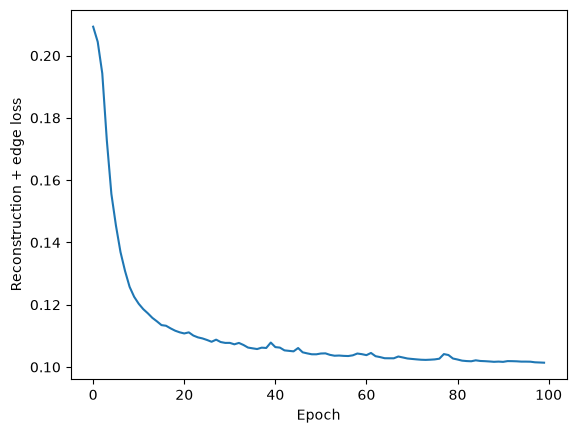

In [4]:
# Tiny exploratory training run; increase epochs when you have more artwork.
EPOCHS = 100
losses = []
model.train()
for epoch in range(EPOCHS):
    total = 0.0
    for indices in torch.randperm(len(x)).split(8):
        batch = x[indices]
        notes, reconstructed = model(batch)
        loss = reconstruction_loss(reconstructed, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(batch)
    losses.append(total / len(x))
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS}: loss = {losses[-1]:.4f}")
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction + edge loss")
plt.show()


## Compare more paintings (no retraining)

Set `START` and `COUNT` to page through the dataset, or set `FAMILY = "oil-paint"` / `"pastel"` / `"unknown"`. Originals retain their proportions here; the training input is still stretched to 64 × 64. The error map is mean absolute RGB error on a fixed 0–1 scale, not per-image contrast normalization. Note grids also share a fixed 0–1 scale.

Compare **original → training input** for detail lost before learning, and **training input → reconstruction** for detail lost by the model. These are training examples, not held-out evaluations. Set `PLAY_AUDIO = True` after running the playback cell to hear each gallery painting.


INDEX = 0: oil-paint/'En_promenade_près_d'Argenteuil'_by_Claude_Monet,_1875.jpg
INDEX = 1: oil-paint/3607_Paisaje_en_Port-Villez.jpg
INDEX = 2: oil-paint/Claude_Monet,_The_Portal_of_Rouen_Cathedral,_le_Portal_vu_de_face_(cropped).jpg
INDEX = 3: oil-paint/Claude_Monet_-_Bord_des_falaises_à_Pourville.jpg
INDEX = 4: oil-paint/Claude_Monet_-_Effet_de_neige_à_Vétheul.jpg
INDEX = 5: oil-paint/Claude_Monet_-_La_Cabane_des_Douaniers_a_Pourville_(1882).jpg


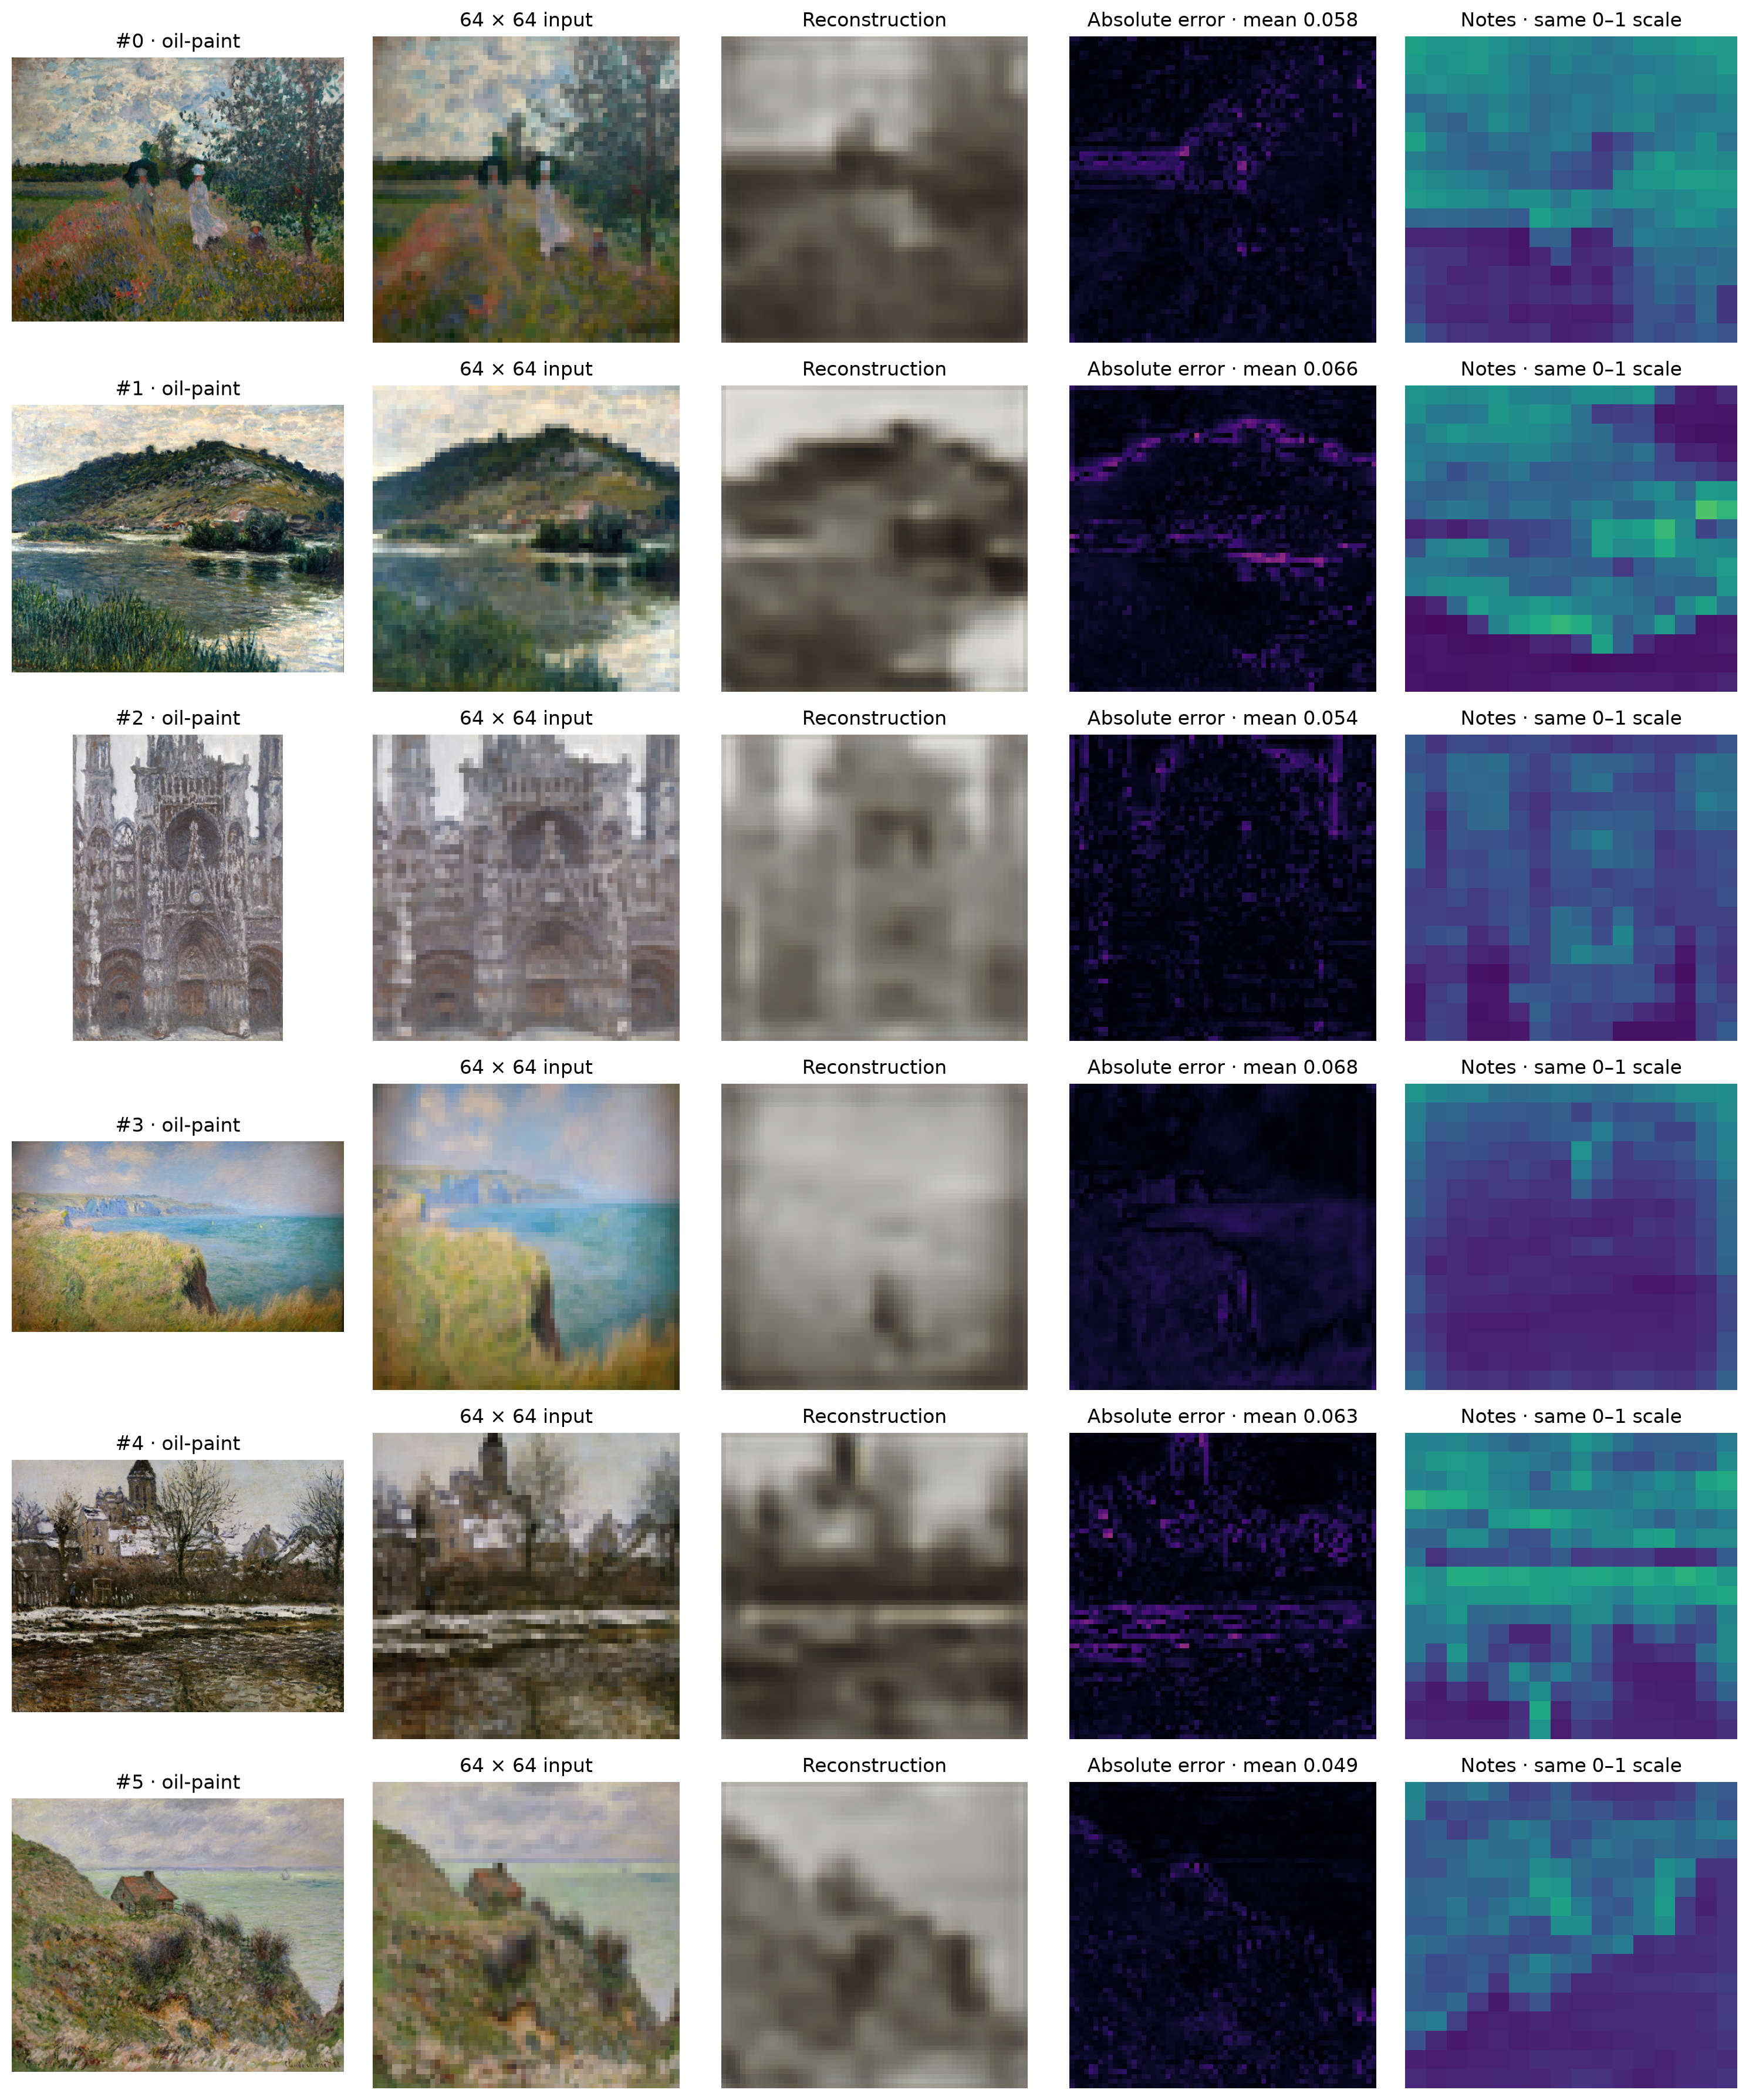

In [8]:
START = 0
COUNT = 6
FAMILY = None  # Or "oil-paint", "pastel", "unknown".
PLAY_AUDIO = False

candidates = [i for i, path in enumerate(paths) if FAMILY is None or path.parent.name == FAMILY]
selected = candidates[START:START + COUNT]
assert selected, "No paintings on this page; check START and FAMILY."
model.eval()
with torch.no_grad():
    gallery_notes, gallery_recon = model(x[selected])
fig, axes = plt.subplots(len(selected), 5, figsize=(15, 3 * len(selected)), squeeze=False)
for row, index in enumerate(selected):
    with Image.open(paths[index]) as image:
        original = ImageOps.exif_transpose(image).convert("RGB")
        original.thumbnail((512, 512))
        axes[row, 0].imshow(original)
    axes[row, 1].imshow(x[index].permute(1, 2, 0).numpy())
    axes[row, 2].imshow(gallery_recon[row].permute(1, 2, 0).numpy())
    error = (gallery_recon[row] - x[index]).abs().mean(dim=0).numpy()
    axes[row, 3].imshow(error, cmap="magma", vmin=0, vmax=1)
    axes[row, 4].imshow(gallery_notes[row, 0].numpy(), origin="lower", vmin=0, vmax=1, aspect="auto")
    titles = [f"#{index} · {paths[index].parent.name}", "64 × 64 input", "Reconstruction",
              f"Absolute error · mean {error.mean():.3f}", "Notes · same 0–1 scale"]
    for axis, title in zip(axes[row], titles):
        axis.set_title(title)
        axis.axis("off")
    print(f"INDEX = {index}: {paths[index].relative_to(ROOT)}")
plt.tight_layout()
plt.show()
if PLAY_AUDIO:
    assert "sonify" in globals(), "Run the playback cell first."
    for row, index in enumerate(selected):
        print(f"#{index}: {paths[index].name}")
        display(Audio(sonify(gallery_notes[row, 0].numpy(), scale=SCALE, root=ROOT_MIDI), rate=22050))


## Look and listen — dominant-feature melody

One pitch per column (argmax), with adjacent identical pitches sustained. White segments show the selected melody on each grid. Change `SCALE`, `ROOT_MIDI`, or `MELODY_THRESHOLD` and rerun playback; no retraining. `SHOW_GALLERY = True` plays the gallery page, defaulting to the first six paintings when no page settings exist. Each step remains 0.15 seconds; amplitudes are averaged over sustained notes and playback is peak-normalized.


0: oil-paint/'En_promenade_près_d'Argenteuil'_by_Claude_Monet,_1875.jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


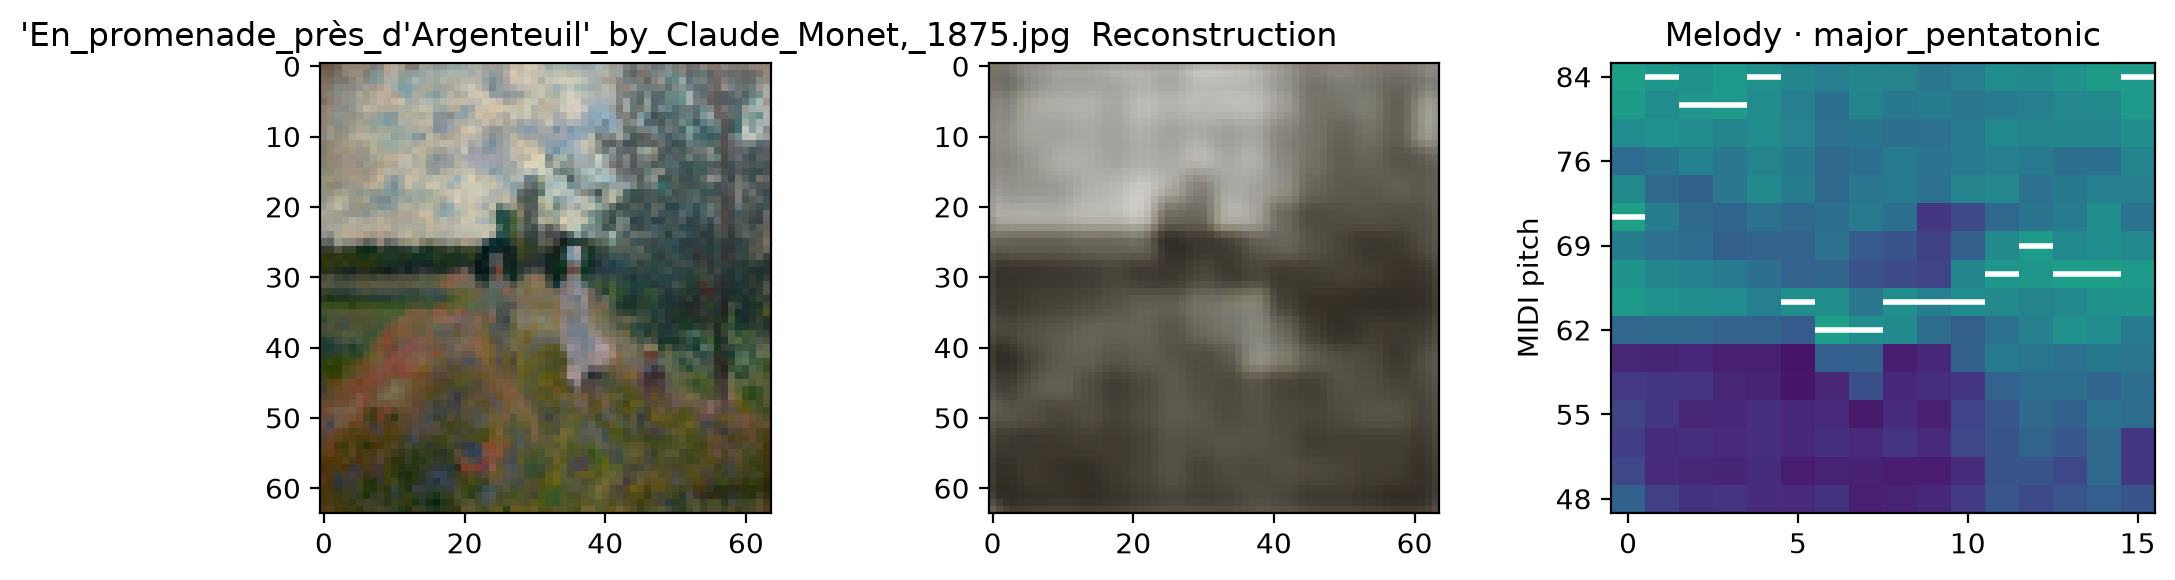

1: oil-paint/3607_Paisaje_en_Port-Villez.jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


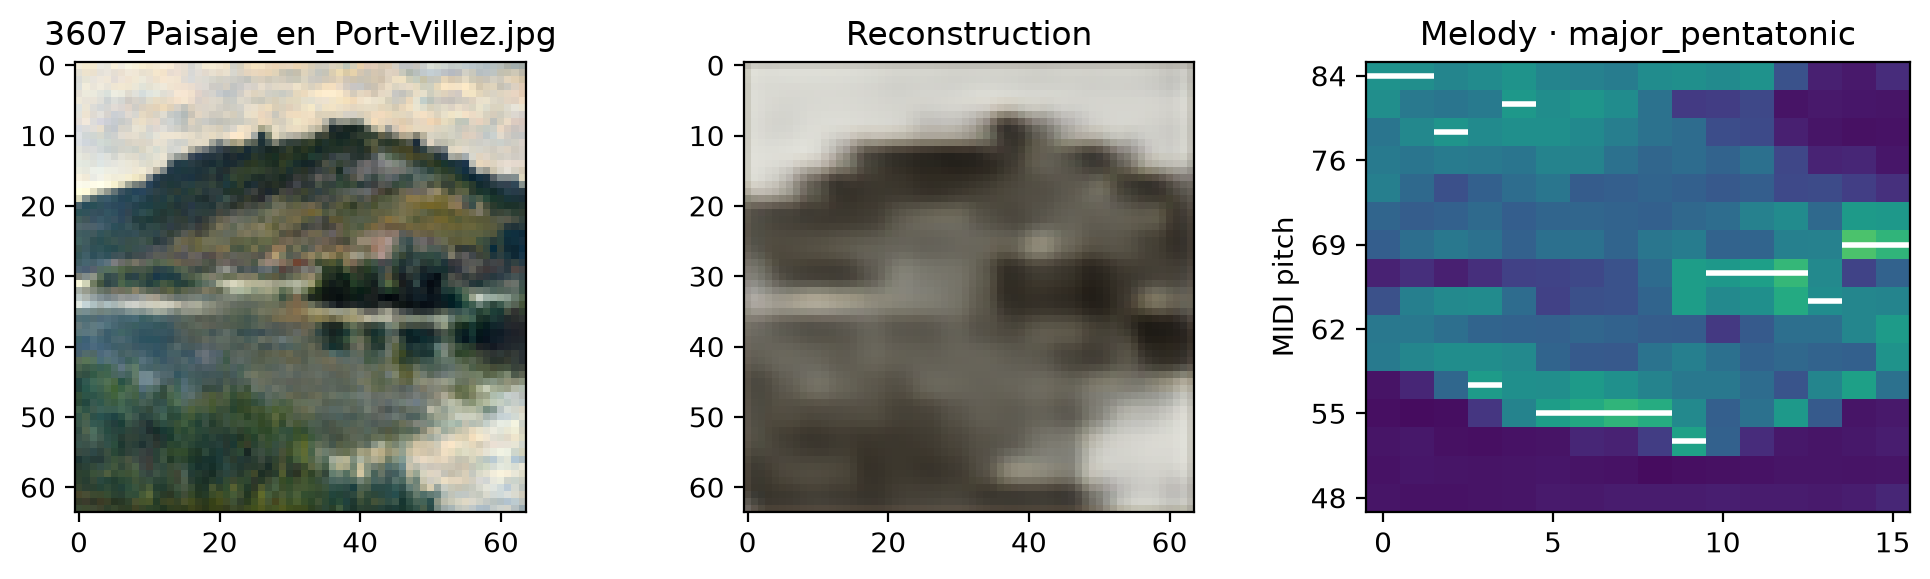

2: oil-paint/Claude_Monet,_The_Portal_of_Rouen_Cathedral,_le_Portal_vu_de_face_(cropped).jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


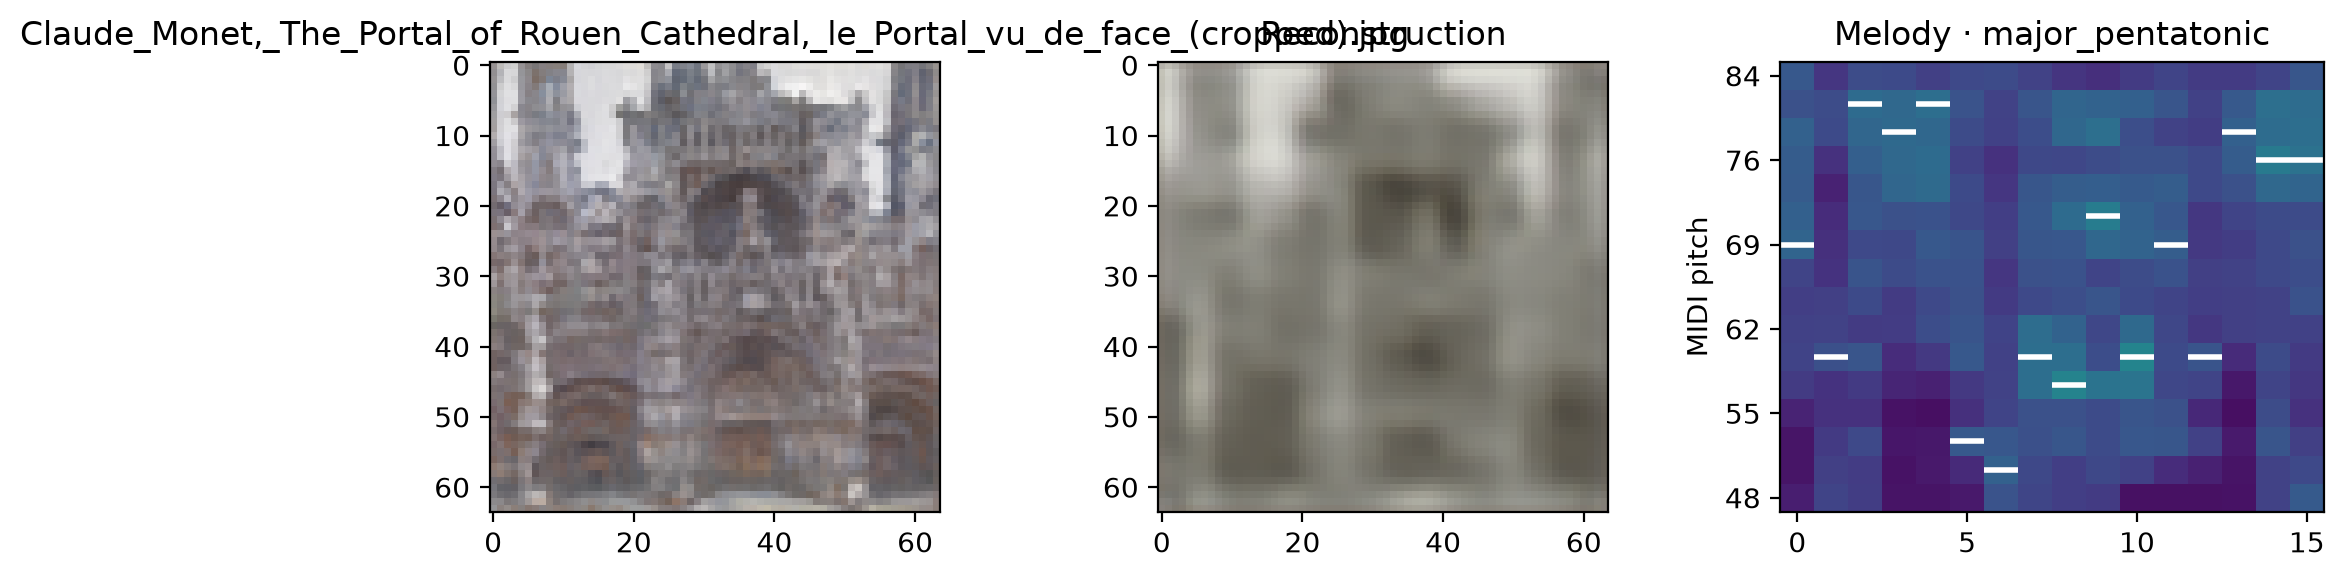

3: oil-paint/Claude_Monet_-_Bord_des_falaises_à_Pourville.jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


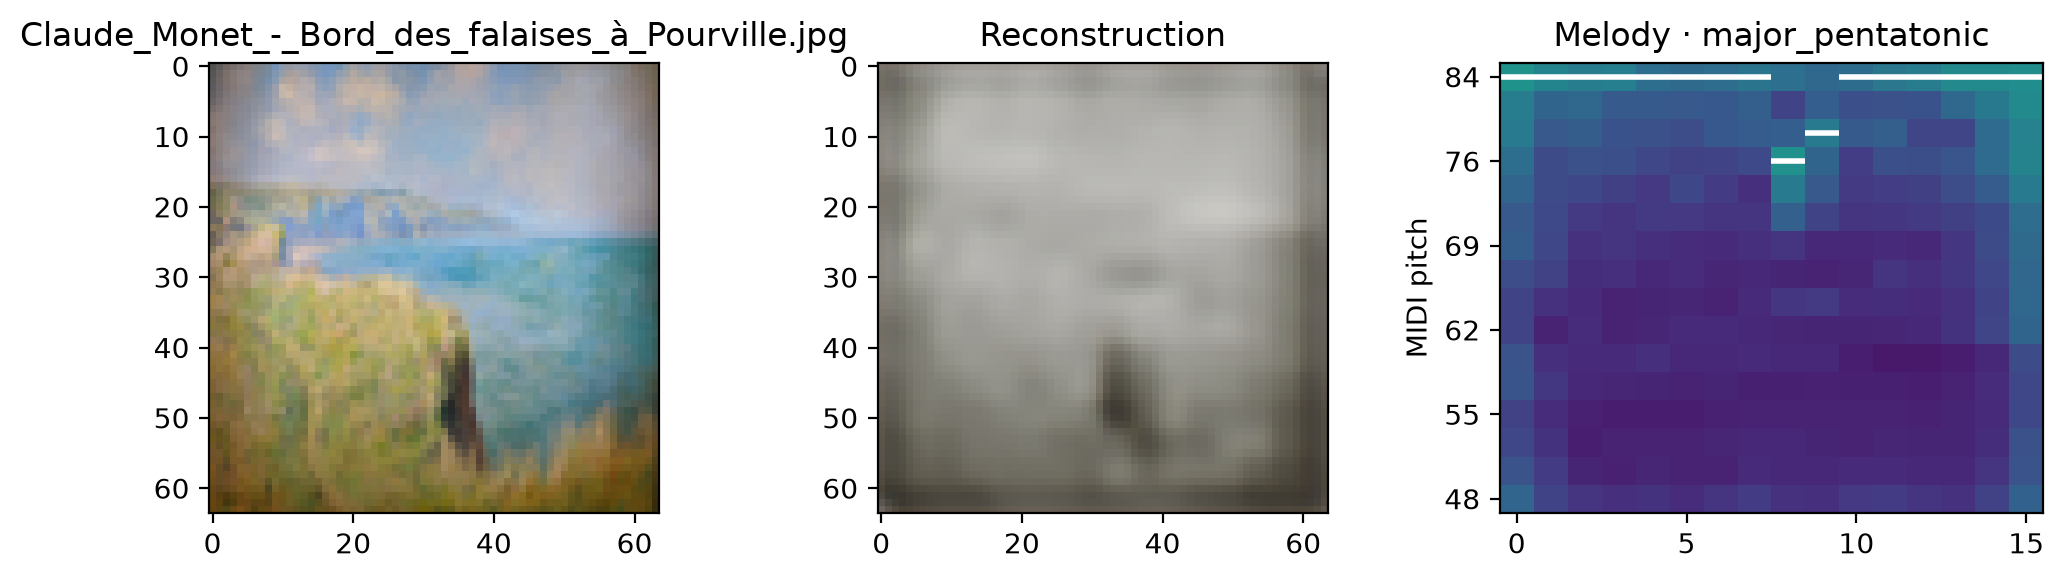

4: oil-paint/Claude_Monet_-_Effet_de_neige_à_Vétheul.jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


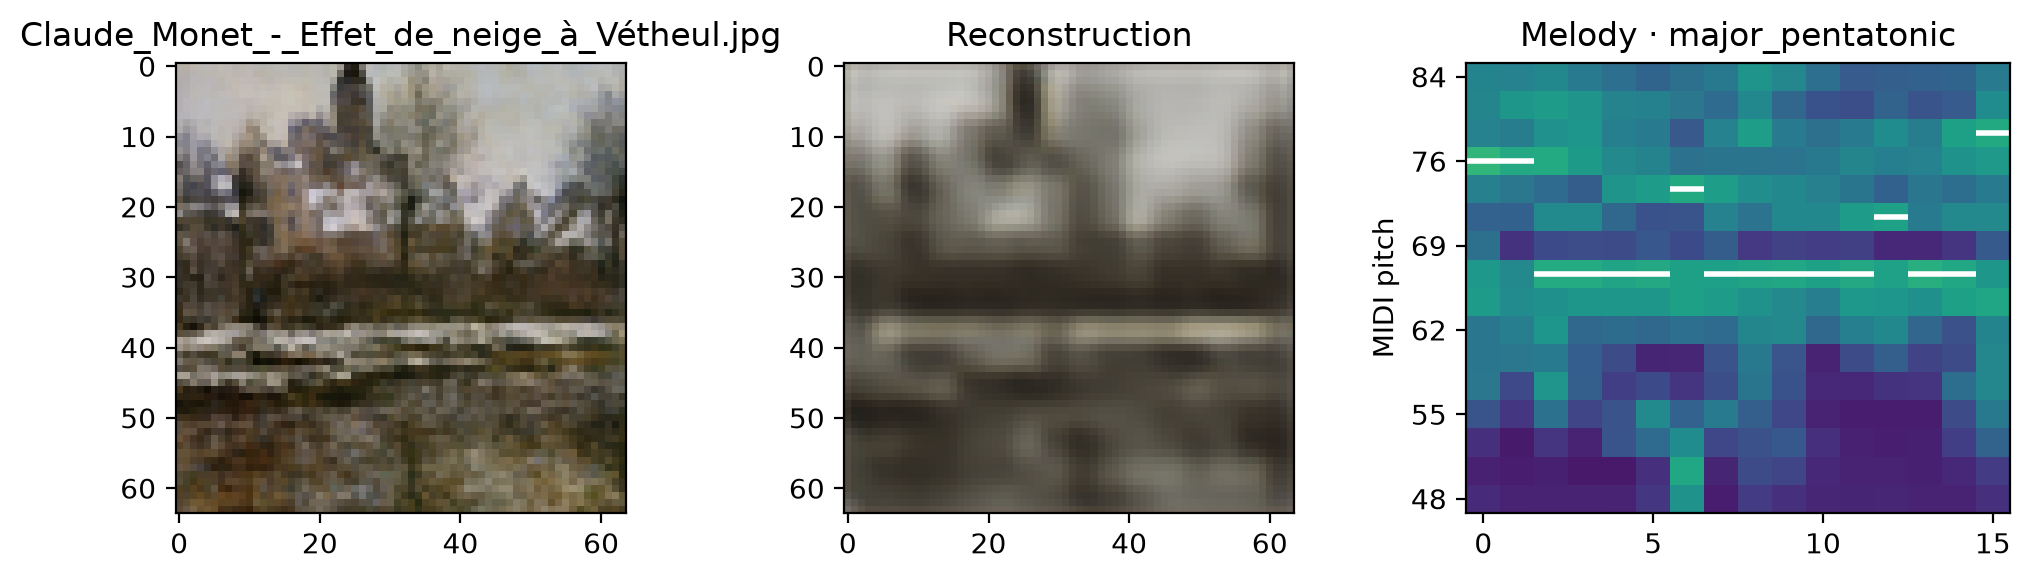

5: oil-paint/Claude_Monet_-_La_Cabane_des_Douaniers_a_Pourville_(1882).jpg
major_pentatonic, root MIDI 48; pitches: [48, 50, 52, 55, 57, 60, 62, 64, 67, 69, 72, 74, 76, 79, 81, 84]


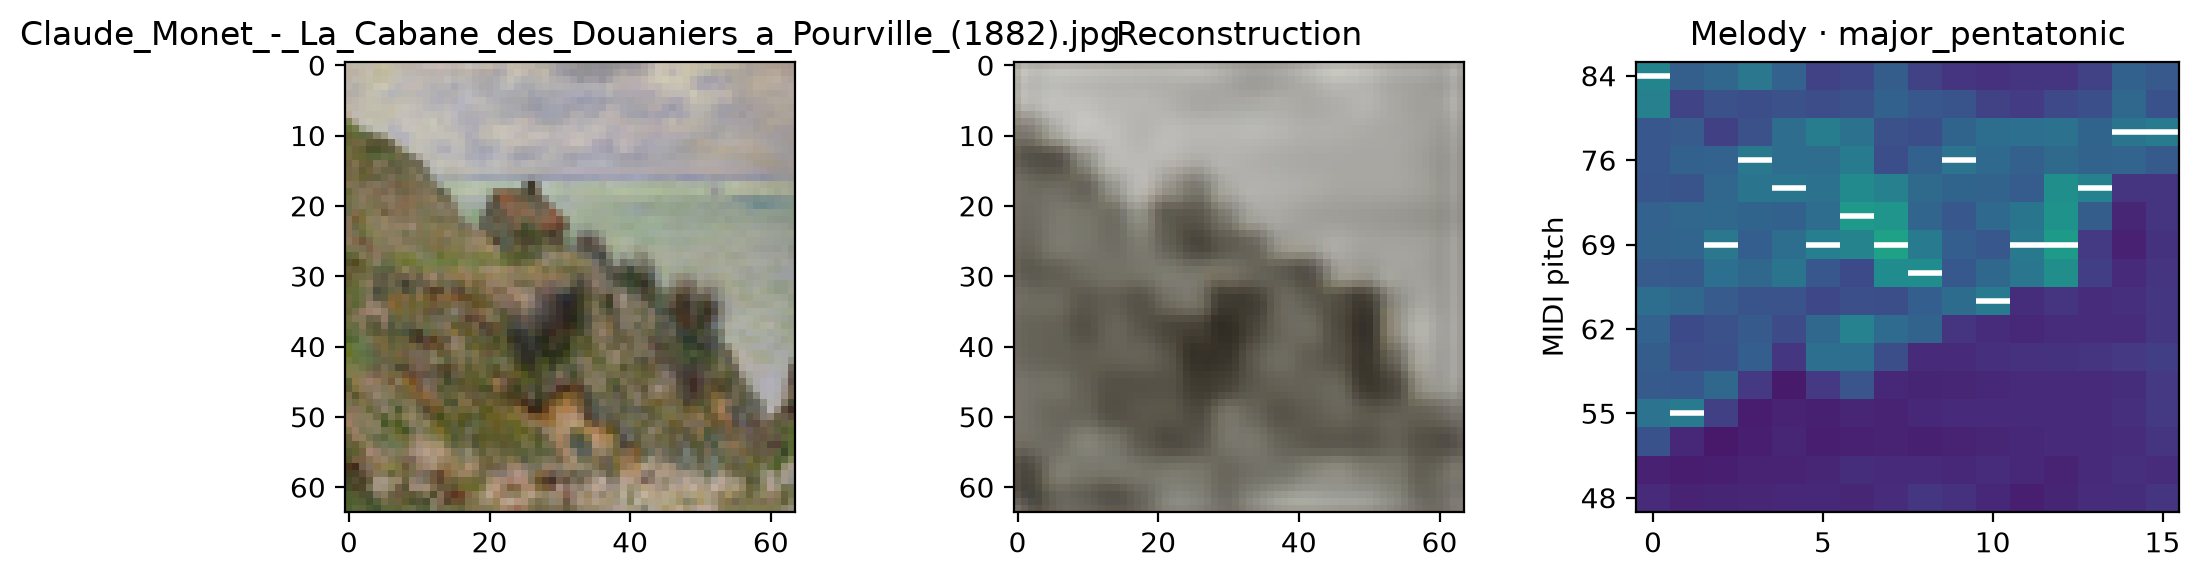

In [11]:
SCALES = {
    "chromatic": list(range(12)),
    "major": [0, 2, 4, 5, 7, 9, 11],
    "minor": [0, 2, 3, 5, 7, 8, 10],
    "major_pentatonic": [0, 2, 4, 7, 9],
    "minor_pentatonic": [0, 3, 5, 7, 10],
}


def scale_notes(rows, scale, root):
    if scale not in SCALES:
        raise ValueError(f"Choose a scale from {list(SCALES)}")
    intervals = SCALES[scale]
    notes = [root + intervals[k % len(intervals)] + 12 * (k // len(intervals))
             for k in range(rows)]
    if not all(0 <= note <= 127 for note in notes):
        raise ValueError("Choose a root that keeps all notes within MIDI 0–127.")
    return notes


from pathlib import Path
import sys, importlib
HERE = next(p / "musician" for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "musician/experiment_utils.py").is_file())
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import experiment_utils
importlib.reload(experiment_utils)  # Pick up playback updates in an existing kernel.
from experiment_utils import sonify, melody_events, synthesize_events, export_sound

INDEX = 0
SCALE = "major_pentatonic"  # Try "minor", "major", or "chromatic".
ROOT_MIDI = 48  # C3
MELODY_THRESHOLD = 0.0  # Silence steps whose strongest value is <= this.
SHOW_GALLERY = True  # False = only INDEX; True = current gallery page.
# Use gallery settings if present; otherwise default to the first six paintings.
required = ("model", "x", "paths", "ROOT")
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the data-loading, model, and training cells first. Missing: " + ", ".join(missing))
page_start = globals().get("START", 0)
page_count = globals().get("COUNT", 6)
page_family = globals().get("FAMILY", None)
listen_indices = [i for i, path in enumerate(paths)
                  if page_family is None or path.parent.name == page_family]
listen_indices = listen_indices[page_start:page_start + page_count] if SHOW_GALLERY else [INDEX]
assert listen_indices, "No paintings selected; check START, COUNT, and FAMILY."
model.eval()
for image_index in listen_indices:
    print(f"{image_index}: {paths[image_index].relative_to(ROOT)}")
    model.eval()
    with torch.no_grad():
        notes, reconstructed = model(x[image_index:image_index + 1])
    image_grid = notes[0, 0].numpy()
    pitches = scale_notes(image_grid.shape[0], SCALE, ROOT_MIDI)
    print(f"{SCALE}, root MIDI {ROOT_MIDI}; pitches: {pitches}")
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(x[image_index].permute(1, 2, 0).numpy())
    axes[0].set_title(paths[image_index].name)
    axes[1].imshow(reconstructed[0].permute(1, 2, 0).numpy())
    axes[1].set_title("Reconstruction")
    axes[2].imshow(image_grid, origin="lower", aspect="auto", vmin=0, vmax=1)
    events = melody_events(image_grid, SCALE, ROOT_MIDI, MELODY_THRESHOLD)
    for event in events:
        if event['row'] is not None:
            axes[2].hlines(event['row'], event['start'] - 0.5,
                           event['start'] + event['steps'] - 0.5, color="white", linewidth=2)
    axes[2].set_title(f"Melody · {SCALE}")
    axes[2].set_yticks(range(0, len(pitches), 3), pitches[::3])
    axes[2].set_ylabel("MIDI pitch")
    plt.tight_layout()
    plt.show()
    display(Audio(sonify(image_grid, scale=SCALE, root=ROOT_MIDI, threshold=MELODY_THRESHOLD), rate=22050))

# Keep the single-image grid available for other experiments.
with torch.no_grad():
    grid = model(x[INDEX:INDEX + 1])[0][0, 0].numpy()


## Sheet music — same melody as audio

Run after Look and listen. One note at a time; consecutive identical pitches become a sustained note. Each grid step is a sixteenth at 100 BPM. `NOTE_THRESHOLD` inherits the playback threshold so both use the same melody events; increasing it adds rests. MusicXML may split long durations into tied notes. `SHEET_GALLERY` controls one painting versus the current page. SVG and MusicXML are saved under `musician/output/`.


#0: oil-paint/'En_promenade_près_d'Argenteuil'_by_Claude_Monet,_1875.jpg


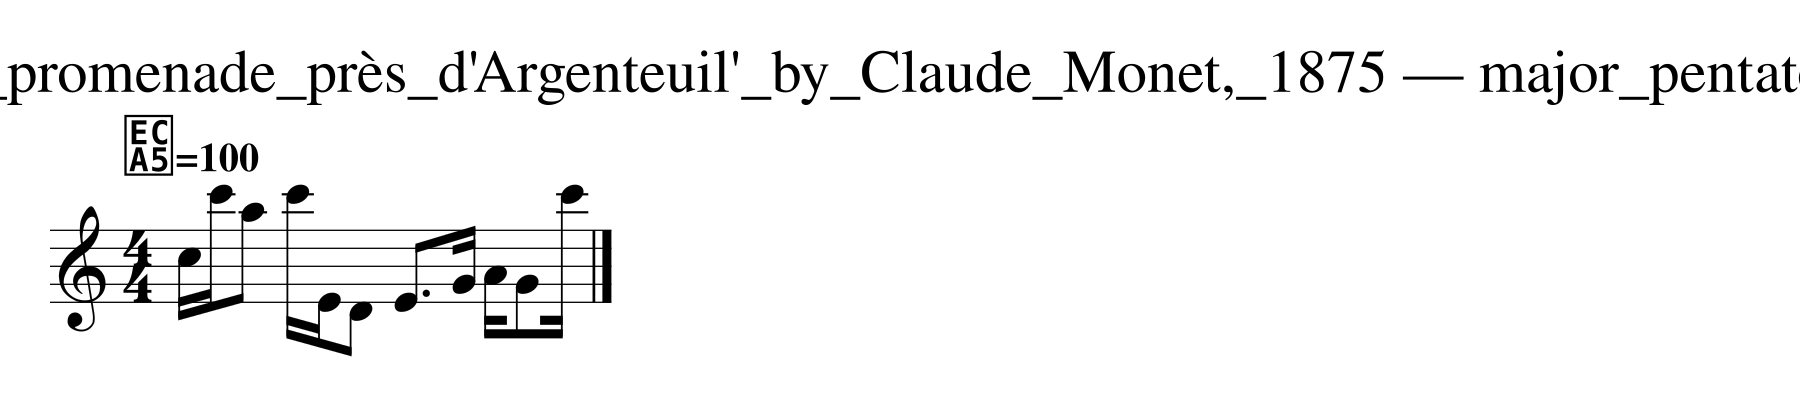

11 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


#1: oil-paint/3607_Paisaje_en_Port-Villez.jpg


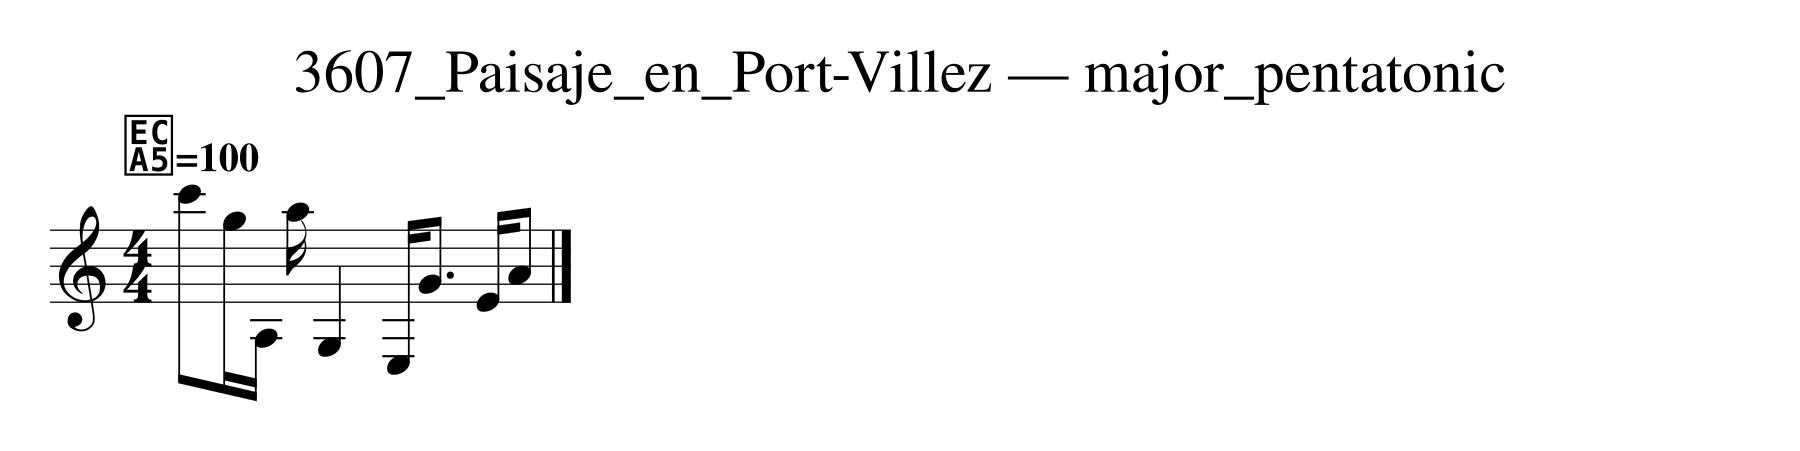

9 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


#2: oil-paint/Claude_Monet,_The_Portal_of_Rouen_Cathedral,_le_Portal_vu_de_face_(cropped).jpg


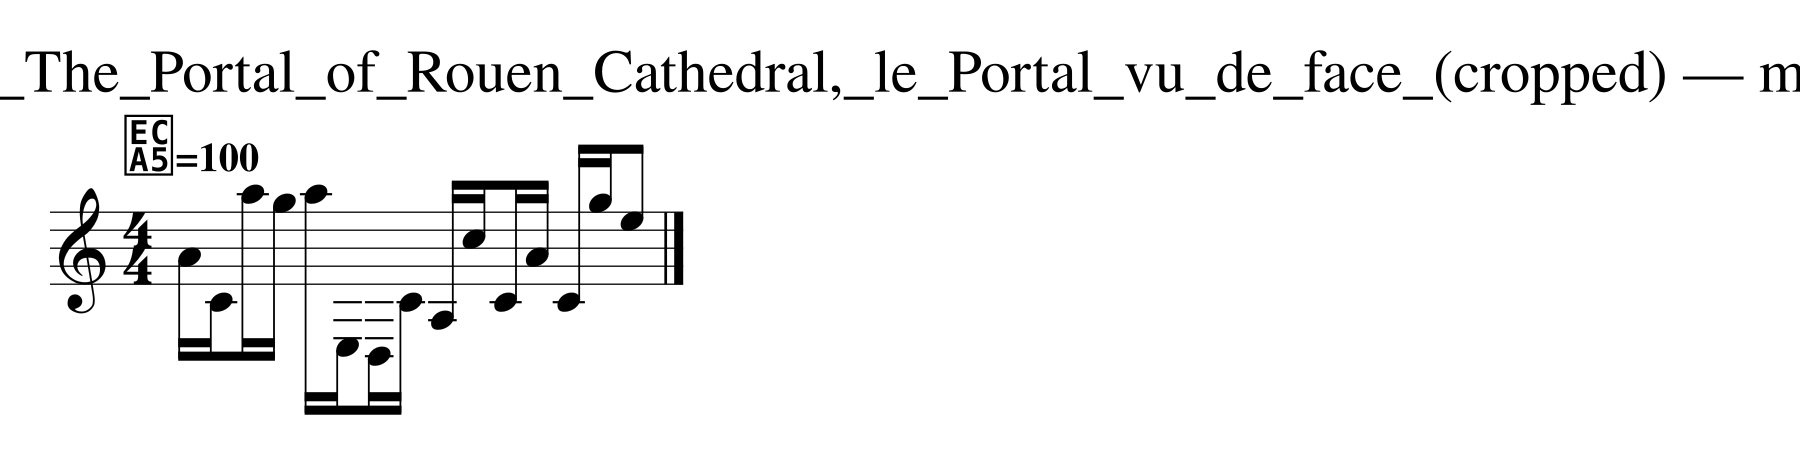

15 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


#3: oil-paint/Claude_Monet_-_Bord_des_falaises_à_Pourville.jpg


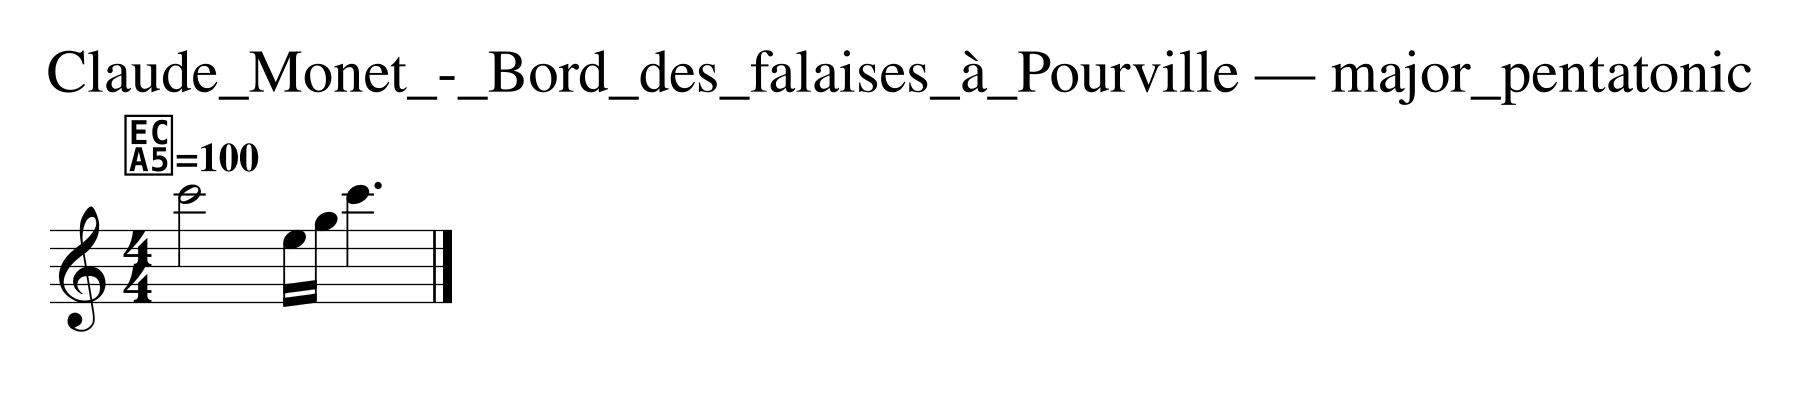

4 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


#4: oil-paint/Claude_Monet_-_Effet_de_neige_à_Vétheul.jpg


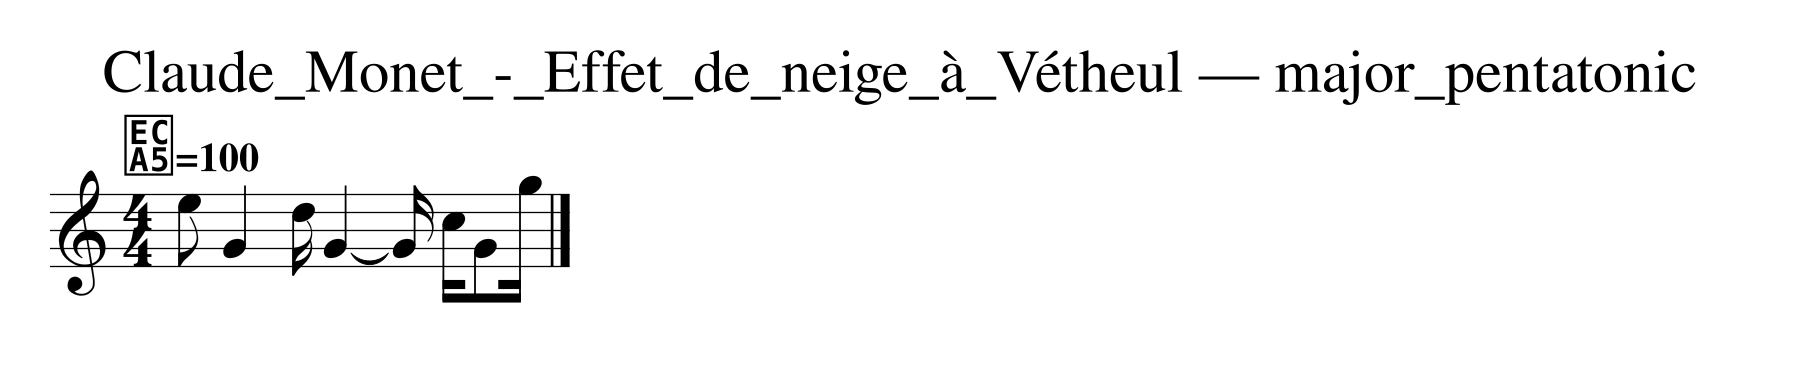

7 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


#5: oil-paint/Claude_Monet_-_La_Cabane_des_Douaniers_a_Pourville_(1882).jpg


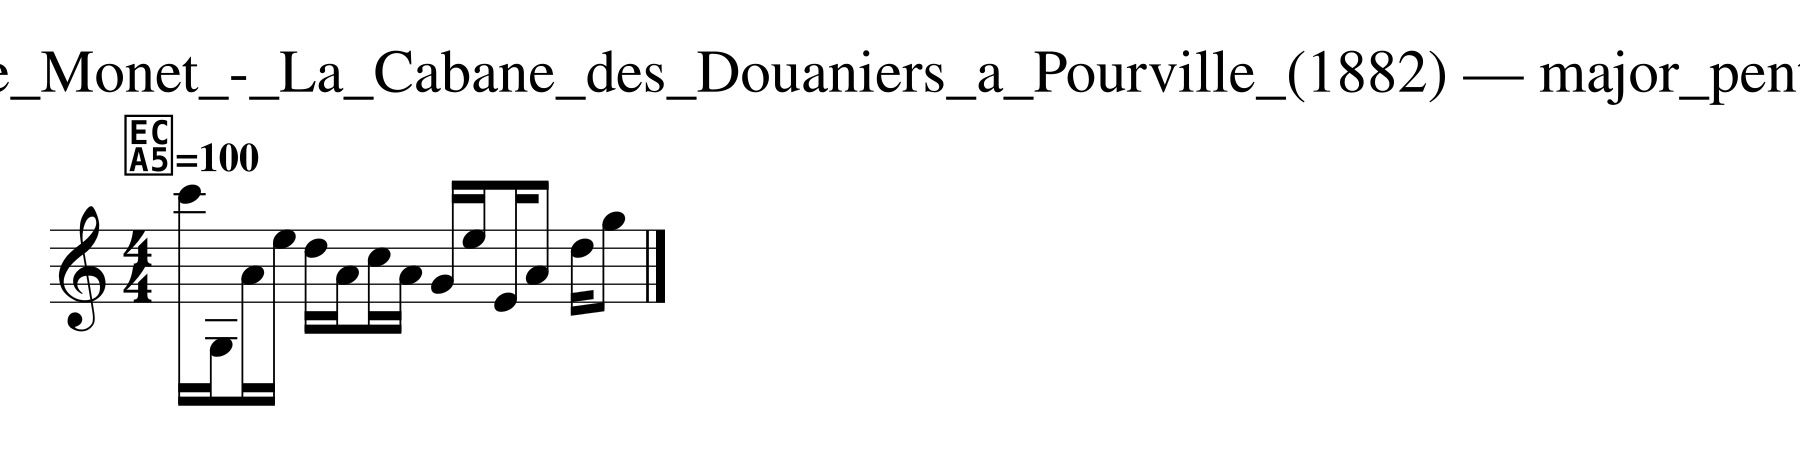

14 melody/rest events; exported to /Users/sarinali/Projects/3d-painting/musician/output


In [12]:
from music21 import stream, note, chord, clef, meter, tempo, metadata, layout
from music21.musicxml.m21ToXml import GeneralObjectExporter
import verovio
from IPython.display import SVG

NOTE_THRESHOLD = MELODY_THRESHOLD  # Same rests as playback by default.
assert 0 <= NOTE_THRESHOLD <= 1
SHEET_GALLERY = True  # False = only INDEX; True = current gallery page.
if "listen_indices" not in globals():
    raise RuntimeError("Run the Look and listen cell before this sheet-music cell.")
sheet_indices = listen_indices if SHEET_GALLERY else [INDEX]
for image_index in sheet_indices:
    print(f"#{image_index}: {paths[image_index].relative_to(ROOT)}")
    model.eval()
    with torch.no_grad():
        image_grid = model(x[image_index:image_index + 1])[0][0, 0].numpy()
    pitches = scale_notes(image_grid.shape[0], SCALE, ROOT_MIDI)
    events = melody_events(image_grid, SCALE, ROOT_MIDI, NOTE_THRESHOLD)
    score = stream.Score()
    score.metadata = metadata.Metadata()
    score.metadata.title = f"{paths[image_index].stem} — {SCALE}"
    part = stream.Part(id="Melody")
    part.insert(0, clef.TrebleClef())
    part.insert(0, meter.TimeSignature("4/4"))
    part.insert(0, tempo.MetronomeMark(number=100))
    for item in events:
        event = note.Rest() if item['pitch'] is None else note.Note(item['pitch'])
        event.quarterLength = item['steps'] * 0.25
        part.append(event)
    score.insert(0, part)
    xml = GeneralObjectExporter(score).parse().decode("utf-8")
    renderer = verovio.toolkit()
    renderer.setOptions({"inputFrom": "musicxml", "pageWidth": 1800, "adjustPageHeight": True})
    assert renderer.loadData(xml), "Could not render MusicXML."
    output = REPO / "musician/output"
    output.mkdir(exist_ok=True)
    stem = f"melody-{paths[image_index].stem}-{SCALE}-root{ROOT_MIDI}-threshold{NOTE_THRESHOLD:g}"
    (output / f"{stem}.musicxml").write_text(xml)
    for page in range(1, renderer.getPageCount() + 1):
        svg = renderer.renderToSVG(page)
        (output / f"{stem}-page{page}.svg").write_text(svg)
        display(SVG(svg))
    print(f"{len(events)} melody/rest events; exported to {output}")
    display(Audio(synthesize_events(events), rate=22050))


This is an exploration, not evidence of a universal painting–music mapping. Reconstruction can encode details in tiny amplitude differences that are hard to hear. Compare multiple paintings and a direct grayscale-to-note baseline before interpreting family differences; use held-out artwork for a later evaluation.


## Do visually similar paintings produce similar melodies?

Run after training and playback; no retraining. Compare an explicit low-resolution RGB appearance measure with both raw-grid distances and musical interval-contour distances. Positive rank correlation means closer-looking images tend to have closer outputs under these particular measures. The permutation check randomizes painting–melody assignments. These are exploratory training-set results, not proof of semantic similarity, generalization, or universal music–art associations. Compare held-out images, direct-image baselines, and multiple training seeds before drawing conclusions. A constant transposed melody has the same interval contour; it does not necessarily sound identical.

Change `INDEX` before running to inspect its three closest visual neighbors.


117 paintings; low-resolution RGB appearance versus:
  learned grid distance: rank correlation = 0.882
  melody interval distance: rank correlation = -0.025
  exploratory two-sided label-permutation p = 0.671


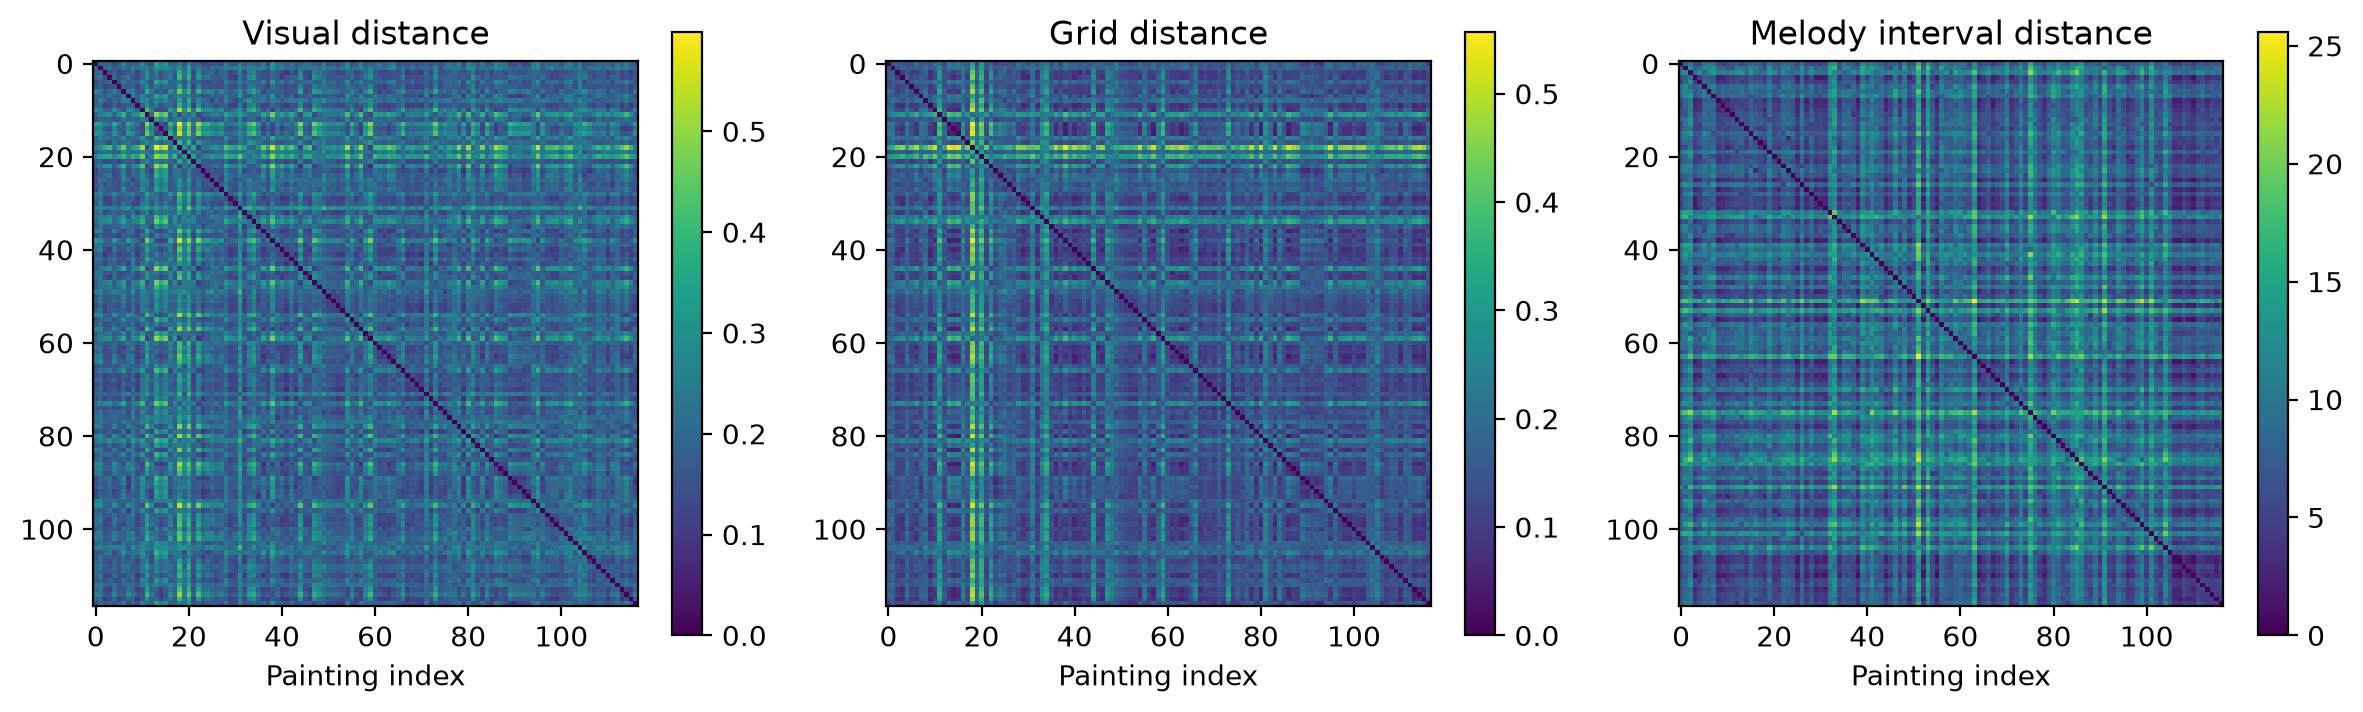

#0: 'En_promenade_près_d'Argenteuil'_by_Claude_Monet,_1875.jpg
#93: Monet_-_Wildenstein_1996,_1885.png
#92: Monet_-_Wildenstein_1996,_1813.png
#52: Claude_Monet_-_Water_Lilies_and_Japanese_Bridge.jpg


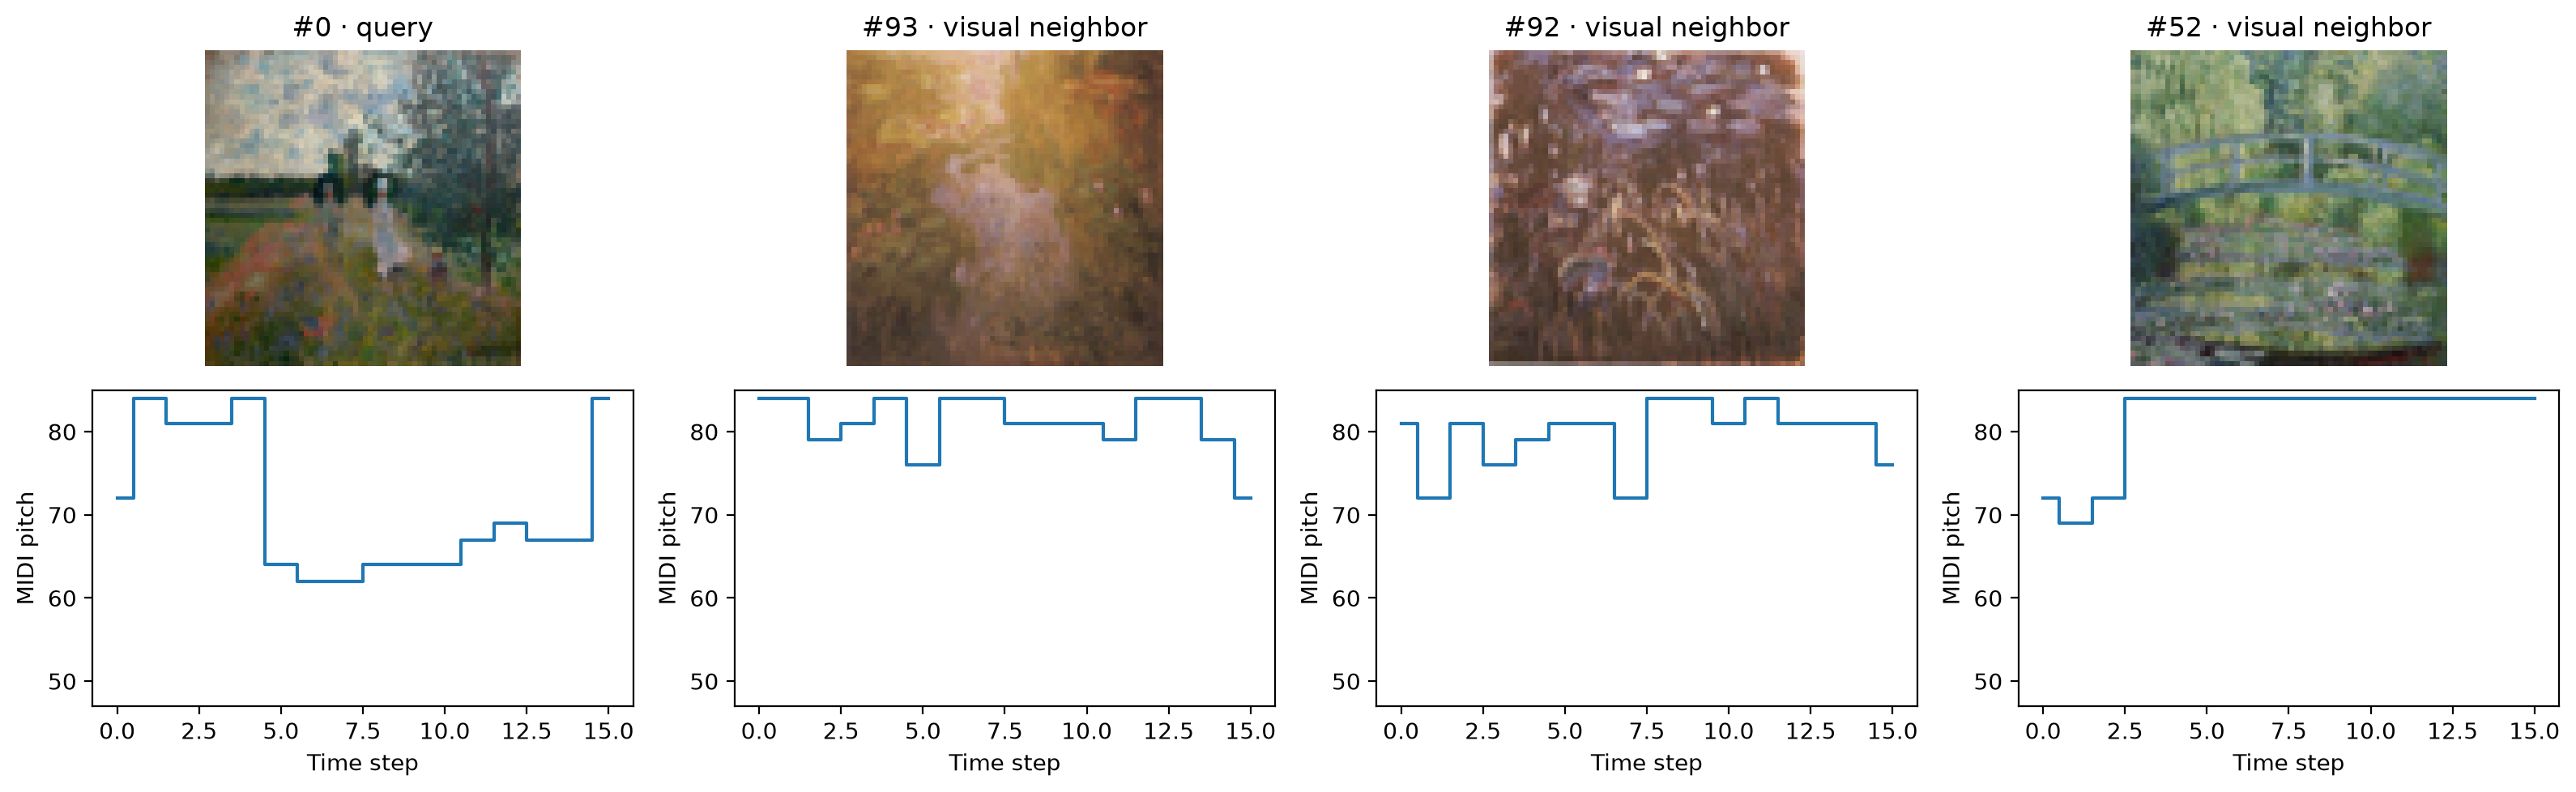

In [13]:
model.eval()
ENCODE = lambda batch: model(batch)[0]
# Run after training. This does not update model weights.
ANALYSIS_COUNT = len(paths)  # All loaded paintings, in the current path order.
PERMUTATIONS = 500
analysis_scale = globals().get("SCALE", "major_pentatonic")
analysis_root = globals().get("ROOT_MIDI", 48)
from experiment_utils import midi_notes
n = min(ANALYSIS_COUNT, len(paths))
assert n >= 4, "Use at least four paintings."
with torch.no_grad():
    all_grids = torch.cat([ENCODE(x[start:min(start + 8, n)])
                           for start in range(0, n, 8)])[:, 0].numpy()
# An independent, explicit visual measure: spatial 16 × 16 RGB appearance.
visual_features = F.adaptive_avg_pool2d(x[:n], (16, 16)).flatten(1).numpy()
pitches = np.array(midi_notes(all_grids.shape[1], analysis_scale, analysis_root))
melody_rows = all_grids.argmax(axis=1)
melody_pitches = pitches[melody_rows]
intervals = np.diff(melody_pitches, axis=1)

def pair_dist(features):
    flat = features.reshape(len(features), -1)
    return np.abs(flat[:, None] - flat[None, :]).mean(axis=2)

def ranks(values):
    _, inverse, counts = np.unique(values, return_inverse=True, return_counts=True)
    middle_ranks = np.cumsum(counts) - (counts + 1) / 2
    return middle_ranks[inverse]

visual_distance = pair_dist(visual_features)
grid_distance = pair_dist(all_grids)
melody_distance = pair_dist(intervals)  # Interval contour; ignores overall transposition.
triangle = np.triu_indices(n, 1)
visual_ranks = ranks(visual_distance[triangle])

def correlation(distance):
    other = ranks(distance[triangle])
    if np.std(visual_ranks) == 0 or np.std(other) == 0:
        return float("nan")
    return float(np.corrcoef(visual_ranks, other)[0, 1])

print(f"{n} paintings; low-resolution RGB appearance versus:")
print(f"  learned grid distance: rank correlation = {correlation(grid_distance):.3f}")
observed = correlation(melody_distance)
print(f"  melody interval distance: rank correlation = {observed:.3f}")
# Shuffle painting↔melody assignments, not individual pair entries.
rng = np.random.default_rng(0)
null = []
for _ in range(PERMUTATIONS):
    order = rng.permutation(n)
    null.append(correlation(melody_distance[np.ix_(order, order)]))
if np.isfinite(observed):
    p = (1 + np.sum(np.abs(null) >= abs(observed))) / (PERMUTATIONS + 1)
    print(f"  exploratory two-sided label-permutation p = {p:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, matrix, title in zip(axes, [visual_distance, grid_distance, melody_distance],
                              ["Visual distance", "Grid distance", "Melody interval distance"]):
    image = axis.imshow(matrix)
    axis.set_title(title)
    axis.set_xlabel("Painting index")
    fig.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

# Inspect the nearest visual neighbors, with melody contours underneath.
i = globals().get("INDEX", 0)
assert 0 <= i < n
neighbors = np.argsort(visual_distance[i])
chosen = [i] + [int(j) for j in neighbors if j != i][:3]
fig, axes = plt.subplots(2, len(chosen), figsize=(4 * len(chosen), 5), squeeze=False)
for col, index in enumerate(chosen):
    axes[0, col].imshow(x[index].permute(1, 2, 0).numpy())
    axes[0, col].set_title(f"#{index}" + (" · query" if index == i else " · visual neighbor"))
    axes[0, col].axis("off")
    axes[1, col].step(range(16), melody_pitches[index], where="mid")
    axes[1, col].set_ylim(pitches.min() - 1, pitches.max() + 1)
    axes[1, col].set_xlabel("Time step")
    axes[1, col].set_ylabel("MIDI pitch")
    print(f"#{index}: {paths[index].name}")
plt.tight_layout()
plt.show()


## Trace a note back to pixels

The encoder receptive field is 15 × 15 pixels, with a stride of 4. Output cell `(r, t)` sees input rows `4r−7…4r+7` and columns `4t−7…4t+7`, clipped at boundaries. Argmax compares all pitch rows, so a time step's winner can depend on the whole vertical strip. Position channels add coordinates but do not enlarge the receptive field.

Argmax itself has no useful ordinary gradient. This cell instead differentiates the current winner-minus-runner-up activation margin. It measures local sensitivity, not a causal explanation or a guarantee about larger edits. Model weights are unchanged.


Winner row 3; runner-up row 15; margin 0.1343
Small margins mean the discrete melody can change after a small activation change.


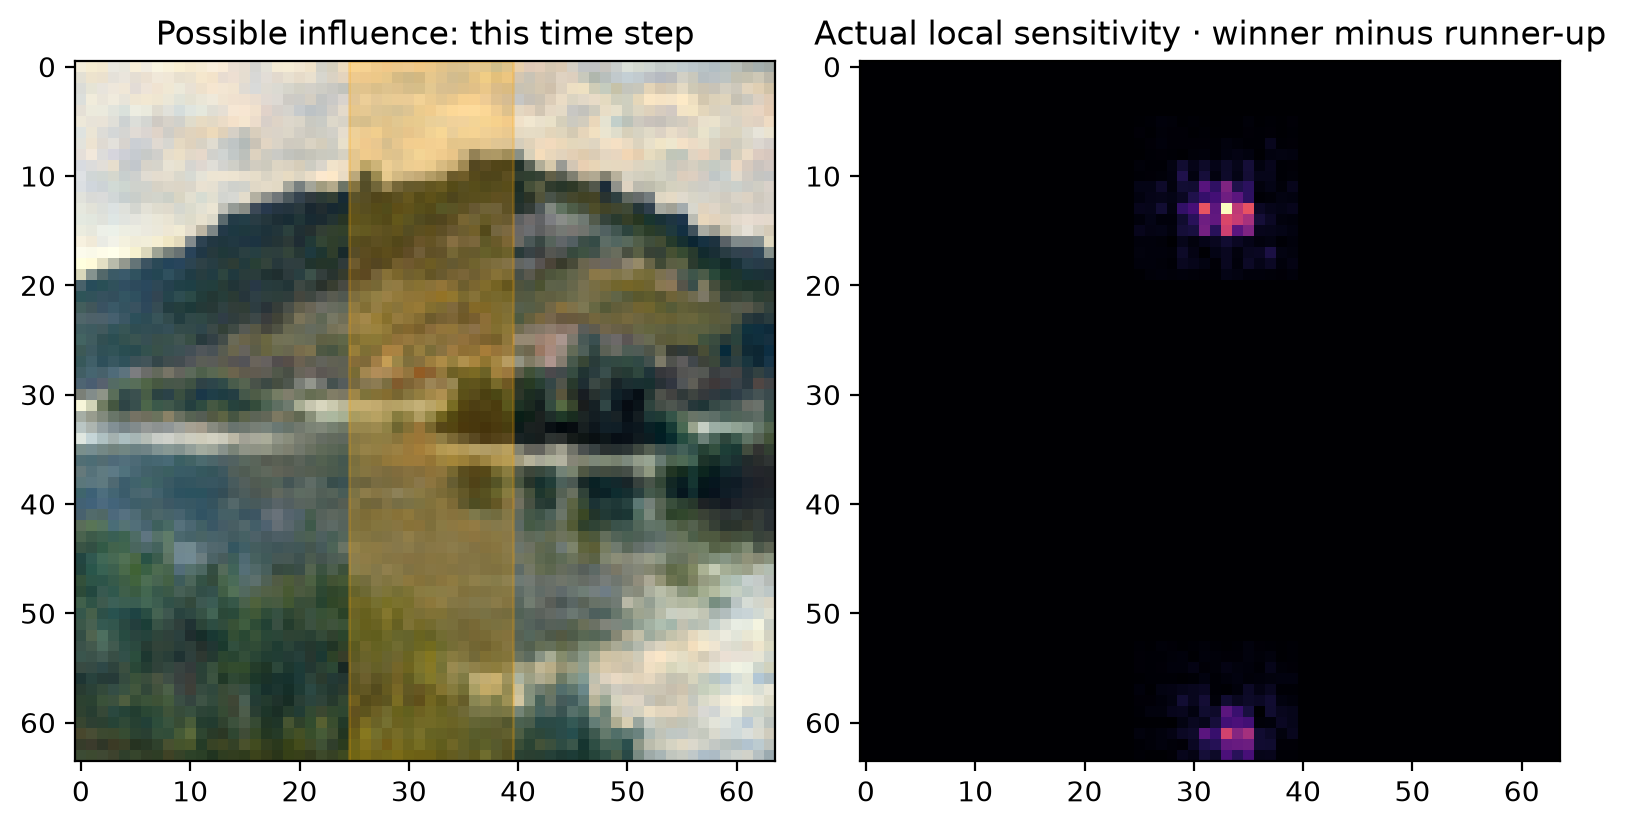

In [14]:
model.eval()
ENCODE = lambda batch: model(batch)[0]
# Which pixels affect the winning pitch's margin over its runner-up?
PAINTING_INDEX = 1
TIME_STEP = 8
assert 0 <= PAINTING_INDEX < len(x) and 0 <= TIME_STEP < 16
sample = x[PAINTING_INDEX:PAINTING_INDEX + 1].detach().clone().requires_grad_(True)
activation = ENCODE(sample)[0, :, :, TIME_STEP].squeeze(0)
winning_rows = activation.detach().topk(2).indices
margin = activation[winning_rows[0]] - activation[winning_rows[1]]
gradient, = torch.autograd.grad(margin, sample)
importance = gradient[0].abs().sum(dim=0).numpy()
print(f"Winner row {int(winning_rows[0])}; runner-up row {int(winning_rows[1])}; margin {margin.item():.4f}")
print("Small margins mean the discrete melody can change after a small activation change.")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample.detach()[0].permute(1, 2, 0).numpy())
# Column t can depend only on x coordinates 4t−7 ... 4t+7, clipped to image.
left, right = max(0, 4 * TIME_STEP - 7), min(63, 4 * TIME_STEP + 7)
axes[0].axvspan(left - .5, right + .5, alpha=.25, color="orange")
axes[0].set_title("Possible influence: this time step")
axes[1].imshow(importance, cmap="magma")
axes[1].set_title("Actual local sensitivity · winner minus runner-up")
plt.tight_layout()
plt.show()
